**Linear LogReg probe PCA on English 5000 data ONLY ON MBERT, new surprise and fear w/o emojis and clean code and BRIGHTER+XED English + German test set + mDeBERTa, with BALANCED calibration AND (printed) PROBE WEIGHTS! ALSO ADDED EVALUATION TO PROJECTION METHODS (+ probe). Additional German calibration and a 6D classifier + probe training on hand labeled data. Estonian is smaller. CORRECT ONE!!**

In [1]:
import pandas as pd
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModel
from tqdm import tqdm
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score, f1_score
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_FILE = "combined_english_cleaned_surprise_and_fear_balanced.csv"
MAX_LENGTH = 128
BATCH_SIZE = 32
RANDOM_STATE = 42

In [3]:
# Pooling

def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output.last_hidden_state
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()

    summed = torch.sum(token_embeddings * input_mask_expanded, dim=1)
    counts = torch.clamp(input_mask_expanded.sum(dim=1), min=1e-9)
    return summed / counts

def cls_pooling(model_output):
    return model_output.last_hidden_state[:, 0, :]

In [4]:
# Encoding
def encode_texts(text_list, tokenizer, model, device, batch_size=32, max_length=128):
    mean_embs = []
    cls_embs = []

    with torch.no_grad():
        for i in tqdm(range(0, len(text_list), batch_size), desc="Encoding"):
            batch_texts = text_list[i:i + batch_size]

            encoded = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=max_length,
                return_tensors="pt"
            )
            encoded = {k: v.to(device) for k, v in encoded.items()}

            outputs = model(**encoded)

            mean_emb = mean_pooling(outputs, encoded["attention_mask"])
            cls_emb = cls_pooling(outputs)

            mean_embs.append(mean_emb.cpu().numpy())
            cls_embs.append(cls_emb.cpu().numpy())

    return np.vstack(mean_embs), np.vstack(cls_embs)

In [5]:
# Centroids

def compute_centroids(embeddings, df, emotion_order):
    centroids = []
    for emotion in emotion_order:
        mask = (df["emotion"] == emotion).values
        centroids.append(embeddings[mask].mean(axis=0))
    centroids = np.vstack(centroids)
    return normalize(centroids, norm="l2")

In [6]:
# PCA

def plot_centroids_in_full_pca_2d(embeddings, centroids, emotion_order, title):
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pca.fit(embeddings)
    centroids_2d = pca.transform(centroids)

    print(f"\n{title}")
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(emotion_order):
        plt.scatter(centroids_2d[i, 0], centroids_2d[i, 1], s=160)
        plt.text(
            centroids_2d[i, 0],
            centroids_2d[i, 1],
            emotion,
            fontsize=11,
            ha='center',
            va='center'
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

def plot_centroids_in_full_pca_3d(embeddings, centroids, emotion_order, title):
    pca = PCA(n_components=3, random_state=RANDOM_STATE)
    pca.fit(embeddings)
    centroids_3d = pca.transform(centroids)

    print(f"\n{title}")
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    for i, emotion in enumerate(emotion_order):
        ax.scatter(
            centroids_3d[i, 0],
            centroids_3d[i, 1],
            centroids_3d[i, 2],
            s=140
        )
        ax.text(
            centroids_3d[i, 0],
            centroids_3d[i, 1],
            centroids_3d[i, 2],
            emotion,
            fontsize=11
        )

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    plt.show()

In [7]:
# Probe training
def train_probe(embeddings, labels, name):
    X_train, X_test, y_train, y_test = train_test_split(
        embeddings,
        labels,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=labels
    )

    clf = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        random_state=RANDOM_STATE,
        class_weight="balanced"
    )
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)

    print(f"\n=== {name} probe ===")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
    print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, y_pred, average="weighted"), 4))
    print(classification_report(y_test, y_pred, digits=3))

    return clf

In [8]:
# Linear probe PCA
def get_probe_space(probe, embeddings, use_probabilities=False):
    if use_probabilities:
        return probe.predict_proba(embeddings)
    else:
        scores = probe.decision_function(embeddings)

        if scores.ndim == 1:
            scores = scores[:, None]

        return scores


def plot_probe_pca_2d(probe, embeddings, labels, emotion_order, title, use_probabilities=False):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_2d = pca.fit_transform(probe_space)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))
    for emotion in emotion_order:
        mask = (np.array(labels) == emotion)
        plt.scatter(
            X_2d[mask, 0],
            X_2d[mask, 1],
            label=emotion,
            alpha=0.35,
            s=10
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


def plot_probe_centroids_pca_2d(probe, embeddings, df, emotion_order, title, use_probabilities=False):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    # centroid in probe space
    centroids = []
    for emotion in emotion_order:
        mask = (df["emotion"] == emotion).values
        centroids.append(probe_space[mask].mean(axis=0))
    centroids = np.vstack(centroids)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pca.fit(probe_space)
    centroids_2d = pca.transform(centroids)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    dx = (centroids_2d[:, 0].max() - centroids_2d[:, 0].min()) * 0.02
    dy = (centroids_2d[:, 1].max() - centroids_2d[:, 1].min()) * 0.02

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(emotion_order):
        plt.scatter(centroids_2d[i, 0], centroids_2d[i, 1], s=180)
        plt.text(
            centroids_2d[i, 0] + dx,
            centroids_2d[i, 1] + dy,
            emotion,
            fontsize=11
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()


def plot_probe_kde_pca_2d(probe, embeddings, labels, emotion_order, title, use_probabilities=True):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_2d = pca.fit_transform(probe_space)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))

    # scatter lightly underneath
    for emotion in emotion_order:
        mask = (np.array(labels) == emotion)
        plt.scatter(
            X_2d[mask, 0],
            X_2d[mask, 1],
            alpha=0.08,
            s=8,
            label=emotion
        )

    # KDE contours if seaborn is available
    try:
        import seaborn as sns

        for emotion in emotion_order:
            mask = (np.array(labels) == emotion)
            sns.kdeplot(
                x=X_2d[mask, 0],
                y=X_2d[mask, 1],
                levels=[0.25, 0.5],
                linewidths=2
            )
    except ImportError:
        print("seaborn not installed, showing scatter only.")

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

In [9]:
# Example prediction
example_texts = [
    "I am so happy and excited about this!",
    "This is disgusting and makes me sick.",
    "I am terrified something bad will happen.",
    "I miss you so much and feel empty.",
    "What a wonderful surprise!",
    "I am furious and cannot stand this anymore."
]

def predict_examples(text_list, tokenizer, model, device, probe, use_mean=True):
    mean_embs, cls_embs = encode_texts(
        text_list, tokenizer, model, device,
        batch_size=8, max_length=MAX_LENGTH
    )

    embs = mean_embs if use_mean else cls_embs
    embs = normalize(embs, norm="l2")

    preds = probe.predict(embs)
    probs = probe.predict_proba(embs)

    for text, pred, prob in zip(text_list, preds, probs):
        top_idx = np.argsort(prob)[::-1][:3]
        top3 = [(probe.classes_[i], round(float(prob[i]), 3)) for i in top_idx]

        print("\nTEXT:", text)
        print("Predicted:", pred)
        print("Top-3:", top3)

In [10]:

# Probe weight analysis

def get_probe_weight_matrix(probe):
    """
    Returns normalized probe weight vectors.
    Shape: (n_classes, hidden_dim)
    """
    if not hasattr(probe, "coef_"):
        raise ValueError("Probe does not expose coef_. This works for LogisticRegression.")
    W = probe.coef_.copy()
    return normalize(W, norm="l2")


def plot_probe_weight_cosine_similarity(probe, class_order, title):
    W = get_probe_weight_matrix(probe)
    sim = cosine_similarity(W)
    sim_df = pd.DataFrame(sim, index=class_order, columns=class_order).round(3)

    print(f"\n{title}")
    print(sim_df)

    plt.figure(figsize=(7, 6))
    plt.imshow(sim, interpolation="nearest")
    plt.xticks(range(len(class_order)), class_order, rotation=45, ha="right")
    plt.yticks(range(len(class_order)), class_order)
    plt.colorbar()
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return sim_df


def plot_probe_weights_pca_2d(probe, class_order, title):
    """
    PCA on probe weight vectors themselves.
    Each point = one emotion direction.
    """
    W = get_probe_weight_matrix(probe)

    # with few classes, max possible rank is limited
    n_comp = min(2, W.shape[0], W.shape[1])
    pca = PCA(n_components=n_comp, random_state=RANDOM_STATE)
    W_2d = pca.fit_transform(W)

    print(f"\n{title}")
    print("Weight matrix shape:", W.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(class_order):
        plt.scatter(W_2d[i, 0], W_2d[i, 1], s=180)
        plt.text(W_2d[i, 0], W_2d[i, 1], emotion, fontsize=11)

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

    return W_2d, pca


def plot_probe_weights_pca_3d(probe, class_order, title):
    W = get_probe_weight_matrix(probe)

    n_comp = min(3, W.shape[0], W.shape[1])
    if n_comp < 3:
        print(f"\n{title}")
        print("Not enough dimensions/classes for 3D PCA.")
        return None, None

    pca = PCA(n_components=3, random_state=RANDOM_STATE)
    W_3d = pca.fit_transform(W)

    print(f"\n{title}")
    print("Weight matrix shape:", W.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    # 🔽 ADD THIS BLOCK
    print("\n3D PCA coordinates (per emotion):")
    coords_df = pd.DataFrame(W_3d, columns=["PC1", "PC2", "PC3"])
    coords_df["emotion"] = class_order
    print(coords_df.round(4).to_string(index=False))

    # Also print in Desmos-friendly format
    print("\nDesmos-friendly format:")
    for i, emotion in enumerate(class_order):
        x, y, z = W_3d[i]
        print(f"{emotion}: ({x:.4f}, {y:.4f}, {z:.4f})")

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    for i, emotion in enumerate(class_order):
        ax.scatter(W_3d[i, 0], W_3d[i, 1], W_3d[i, 2], s=160)
        ax.text(W_3d[i, 0], W_3d[i, 1], W_3d[i, 2], emotion, fontsize=10)

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    plt.show()

    return W_3d, pca


def plot_probe_weights_vs_centroids_pca_2d(probe, centroids, class_order, title):
    """
    Compare probe weight vectors and class centroids in the same PCA space.
    PCA is fit on the combined matrix [weights; centroids].
    """
    W = get_probe_weight_matrix(probe)
    C = normalize(centroids.copy(), norm="l2")

    combined = np.vstack([W, C])

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    combined_2d = pca.fit_transform(combined)

    W_2d = combined_2d[:len(class_order)]
    C_2d = combined_2d[len(class_order):]

    print(f"\n{title}")
    print("Combined shape:", combined.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))

    for i, emotion in enumerate(class_order):
        # weights
        plt.scatter(W_2d[i, 0], W_2d[i, 1], marker="^", s=180)
        plt.text(W_2d[i, 0], W_2d[i, 1], f"{emotion}_W", fontsize=10)

        # centroids
        plt.scatter(C_2d[i, 0], C_2d[i, 1], marker="o", s=180)
        plt.text(C_2d[i, 0], C_2d[i, 1], f"{emotion}_C", fontsize=10)

        # line connecting them
        plt.plot(
            [W_2d[i, 0], C_2d[i, 0]],
            [W_2d[i, 1], C_2d[i, 1]],
            linestyle="--",
            alpha=0.5
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

    return W_2d, C_2d, pca


def plot_probe_weight_projection_histograms(probe, embeddings, labels, emotion_order, title_prefix):
    """
    For each emotion direction, project all embeddings onto that weight vector.
    This shows whether the corresponding class tends to score higher along its own direction.
    """
    W = get_probe_weight_matrix(probe)
    X = normalize(embeddings.copy(), norm="l2")
    label_array = np.array(labels)

    for i, emotion in enumerate(emotion_order):
        scores = X @ W[i]

        plt.figure(figsize=(8, 5))
        for e in emotion_order:
            mask = label_array == e
            plt.hist(scores[mask], bins=40, alpha=0.35, label=e, density=True)

        plt.title(f"{title_prefix}: projection onto '{emotion}' weight")
        plt.xlabel("Cosine-like projection score")
        plt.ylabel("Density")
        plt.legend()
        plt.grid(alpha=0.2)
        plt.show()

In [11]:

# Projection-based classifiers

def get_probe_weight_matrix(probe):
    """
    Returns normalized probe weight vectors.
    Shape: (n_classes, hidden_dim)
    """
    W = probe.coef_.copy()
    return normalize(W, norm="l2")


def predict_with_weight_cosine(embeddings, probe, class_order):
    """
    Classify by cosine similarity between embeddings and probe weight vectors.
    """
    X = normalize(embeddings.copy(), norm="l2")
    W = get_probe_weight_matrix(probe)  # already normalized

    scores = X @ W.T   # cosine-like similarity since both normalized
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores


def predict_with_prototypes(embeddings, centroids, class_order):
    """
    Classify by nearest normalized class centroid (cosine similarity).
    """
    X = normalize(embeddings.copy(), norm="l2")
    C = normalize(centroids.copy(), norm="l2")

    scores = X @ C.T
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores


def softmax_np(x):
    x = x - np.max(x, axis=1, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)


def evaluate_simple_classifier(gold_labels, preds, scores, class_order, name="Classifier"):
    """
    Evaluation for cosine / prototype classifiers.
    Uses softmax(scores) as pseudo-probabilities for log loss + confidence stats.
    """
    probs = softmax_np(scores)

    print(f"\n=== {name} on XED test ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    confidence_df = pd.DataFrame({
        "gold": gold_labels,
        "pred": preds,
        "confidence": pred_conf
    })

    per_class_conf = (
        confidence_df.groupby("gold")["confidence"]
        .agg(["mean", "std", "count"])
        .round(4)
        .rename_axis("emotion")
        .reset_index()
    )

    print("\nPer-class confidence stats:")
    print(per_class_conf.to_string(index=False))

    return {
        "preds": preds,
        "scores": scores,
        "probs": probs,
        "confusion_matrix": cm_df,
        "confidence_stats": per_class_conf,
    }
    
def predict_with_linear_scores(embeddings, probe, class_order, normalize_inputs=False):
    """
    Classify using the probe's raw linear scoring function:
        score_c = x · w_c + b_c

    If normalize_inputs=True, embeddings are L2-normalized first.
    This is still interpretable, but closer to the original logistic probe
    than cosine similarity to normalized weights.
    """
    X = embeddings.copy()
    if normalize_inputs:
        X = normalize(X, norm="l2")

    W = probe.coef_          # shape: (n_classes, dim)
    b = probe.intercept_     # shape: (n_classes,)

    scores = X @ W.T + b
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores

In [12]:
import numpy as np
import pandas as pd

from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Helpers

def softmax_np(scores):
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)


def fit_bias_only(X_calib, y_calib, probe, class_order, l2=0.01):
    """
    Freeze probe weights W, learn only bias b on calibration data.
    """
    W = probe.coef_.copy()
    old_b = probe.intercept_.copy()

    label_to_idx = {label: i for i, label in enumerate(class_order)}
    y_idx = np.array([label_to_idx[y] for y in y_calib])

    def objective(b):
        scores = X_calib @ W.T + b
        probs = softmax_np(scores)

        nll = -np.mean(np.log(probs[np.arange(len(y_idx)), y_idx] + 1e-12))

        # regularize toward original bias, so calibration does not overfit too much
        penalty = l2 * np.sum((b - old_b) ** 2)

        return nll + penalty

    result = minimize(
        objective,
        x0=old_b,
        method="BFGS"
    )

    return result.x


def predict_with_fixed_weights_new_bias(X, probe, new_b, class_order):
    W = probe.coef_.copy()
    scores = X @ W.T + new_b
    probs = softmax_np(scores)

    pred_idx = np.argmax(probs, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, probs, scores


def evaluate_bias_calibrated(X_test, y_test, probe, new_b, class_order, name):
    preds, probs, scores = predict_with_fixed_weights_new_bias(
        X_test,
        probe,
        new_b,
        class_order
    )
    
    
    # Top-3 accuracy
    
    top_k = 3

    # get indices of top-3 predictions per sample
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]

    # map labels to indices
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in y_test])

    # check if gold label is in top-k
    top_k_correct = [
        gold_idx[i] in top_k_preds[i]
        for i in range(len(gold_idx))
    ]

    top_k_acc = np.mean(top_k_correct)

    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "scores": scores,
        "confusion_matrix": cm_df
    }

In [13]:
# mBERT loading

MODEL_NAME = "FacebookAI/xlm-roberta-base"

df = pd.read_csv(DATA_FILE)
df["text"] = df["text"].astype(str)
df["emotion"] = df["emotion"].astype(str)

texts = df["text"].tolist()
labels = df["emotion"].tolist()
emotion_order = sorted(df["emotion"].unique())

print("Rows:", len(df))
print("Emotions:", emotion_order)

device = torch.device("cuda" if torch.cuda.is_available() else "mps")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

Rows: 30000
Emotions: ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']


XLMRobertaModel(
  (embeddings): XLMRobertaEmbeddings(
    (word_embeddings): Embedding(250002, 768, padding_idx=1)
    (position_embeddings): Embedding(514, 768, padding_idx=1)
    (token_type_embeddings): Embedding(1, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): XLMRobertaEncoder(
    (layer): ModuleList(
      (0-11): 12 x XLMRobertaLayer(
        (attention): XLMRobertaAttention(
          (self): XLMRobertaSdpaSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): XLMRobertaSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-05, element

In [14]:
# mBERT info

# embeddings
mean_embeddings, cls_embeddings = encode_texts(
    texts, tokenizer, model, device,
    batch_size=BATCH_SIZE, max_length=MAX_LENGTH
)

print("Mean embeddings shape:", mean_embeddings.shape)
print("CLS embeddings shape:", cls_embeddings.shape)

# normalization
mean_embeddings_norm = normalize(mean_embeddings, norm="l2")
cls_embeddings_norm = normalize(cls_embeddings, norm="l2")  

# centroids
mean_centroids = compute_centroids(mean_embeddings_norm, df, emotion_order)
cls_centroids = compute_centroids(cls_embeddings_norm, df, emotion_order)

# cos similarity
mean_centroid_cos = cosine_similarity(mean_centroids)
cls_centroid_cos = cosine_similarity(cls_centroids)

print("\nCosine similarity between mean-pooled centroids:")
print(pd.DataFrame(mean_centroid_cos, index=emotion_order, columns=emotion_order).round(3))

print("\nCosine similarity between CLS centroids:")
print(pd.DataFrame(cls_centroid_cos, index=emotion_order, columns=emotion_order).round(3))



Encoding: 100%|██████████| 938/938 [05:38<00:00,  2.77it/s]


Mean embeddings shape: (30000, 768)
CLS embeddings shape: (30000, 768)

Cosine similarity between mean-pooled centroids:
          anger  disgust  fear  joy  sadness  surprise
anger       1.0      1.0   1.0  1.0      1.0       1.0
disgust     1.0      1.0   1.0  1.0      1.0       1.0
fear        1.0      1.0   1.0  1.0      1.0       1.0
joy         1.0      1.0   1.0  1.0      1.0       1.0
sadness     1.0      1.0   1.0  1.0      1.0       1.0
surprise    1.0      1.0   1.0  1.0      1.0       1.0

Cosine similarity between CLS centroids:
          anger  disgust  fear  joy  sadness  surprise
anger       1.0      1.0   1.0  1.0      1.0       1.0
disgust     1.0      1.0   1.0  1.0      1.0       1.0
fear        1.0      1.0   1.0  1.0      1.0       1.0
joy         1.0      1.0   1.0  1.0      1.0       1.0
sadness     1.0      1.0   1.0  1.0      1.0       1.0
surprise    1.0      1.0   1.0  1.0      1.0       1.0



Emotion centroids projected into full mean-pooled PCA space
Explained variance ratio: [0.5037 0.0462]


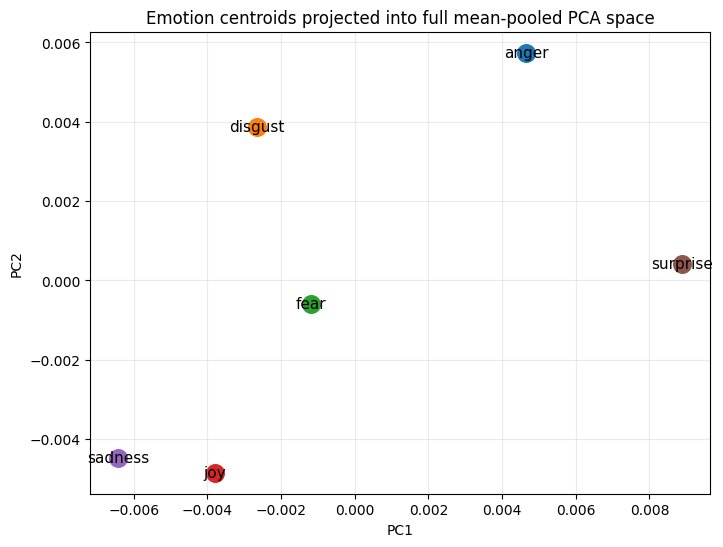


Emotion centroids in 3D PCA space (mean pooled, PCA fit on full data)
Explained variance ratio: [0.5037 0.0462 0.0296]


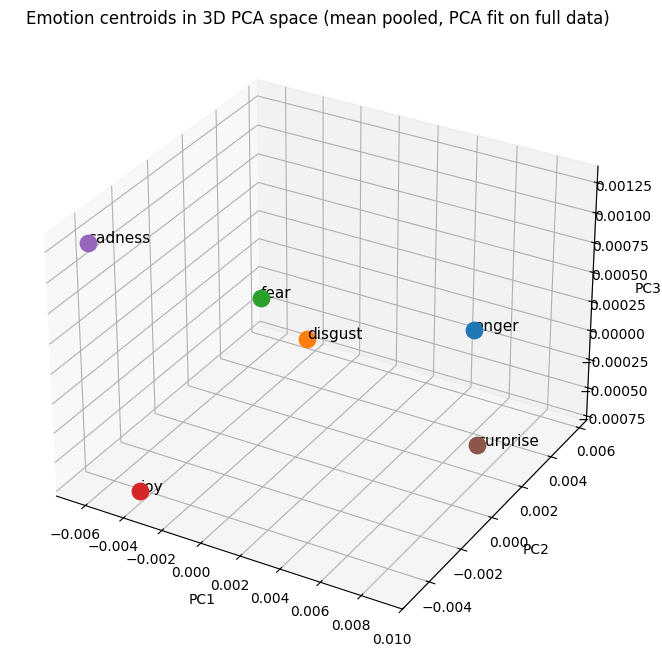


Emotion centroids projected into full CLS PCA space
Explained variance ratio: [0.6756 0.0256]


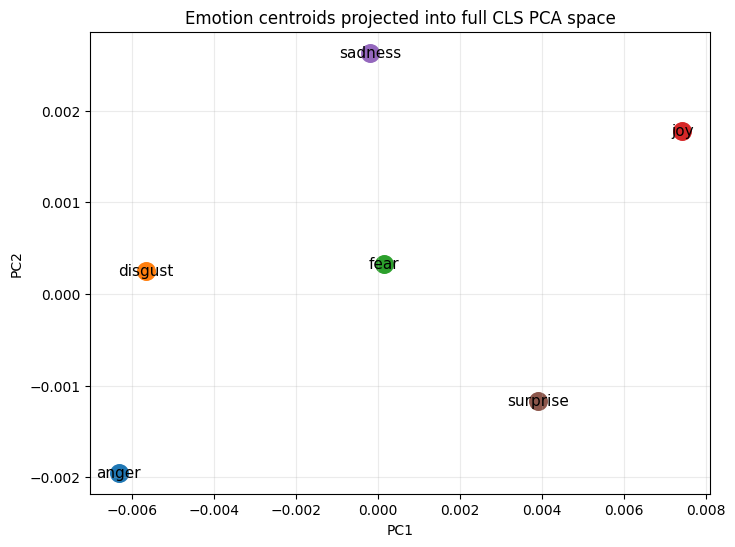

In [15]:
# mBERT visualizations

plot_centroids_in_full_pca_2d(
    mean_embeddings_norm,
    mean_centroids,
    emotion_order,
    "Emotion centroids projected into full mean-pooled PCA space"
)

plot_centroids_in_full_pca_3d(
    mean_embeddings_norm,
    mean_centroids,
    emotion_order,
    "Emotion centroids in 3D PCA space (mean pooled, PCA fit on full data)"
)

# Optional direct comparison with CLS
plot_centroids_in_full_pca_2d(
    cls_embeddings_norm,
    cls_centroids,
    emotion_order,
    "Emotion centroids projected into full CLS PCA space"
)


=== Mean-pooled probe ===
Accuracy: 0.344
Balanced accuracy: 0.344
Macro F1: 0.3221
Weighted F1: 0.3221
              precision    recall  f1-score   support

       anger      0.305     0.348     0.325      1000
     disgust      0.382     0.491     0.430      1000
        fear      0.256     0.053     0.088      1000
         joy      0.432     0.475     0.453      1000
     sadness      0.322     0.458     0.378      1000
    surprise      0.282     0.239     0.259      1000

    accuracy                          0.344      6000
   macro avg      0.330     0.344     0.322      6000
weighted avg      0.330     0.344     0.322      6000


=== CLS probe ===
Accuracy: 0.3238
Balanced accuracy: 0.3238
Macro F1: 0.3044
Weighted F1: 0.3044
              precision    recall  f1-score   support

       anger      0.253     0.451     0.324      1000
     disgust      0.389     0.478     0.429      1000
        fear      0.245     0.059     0.095      1000
         joy      0.391     0.421   

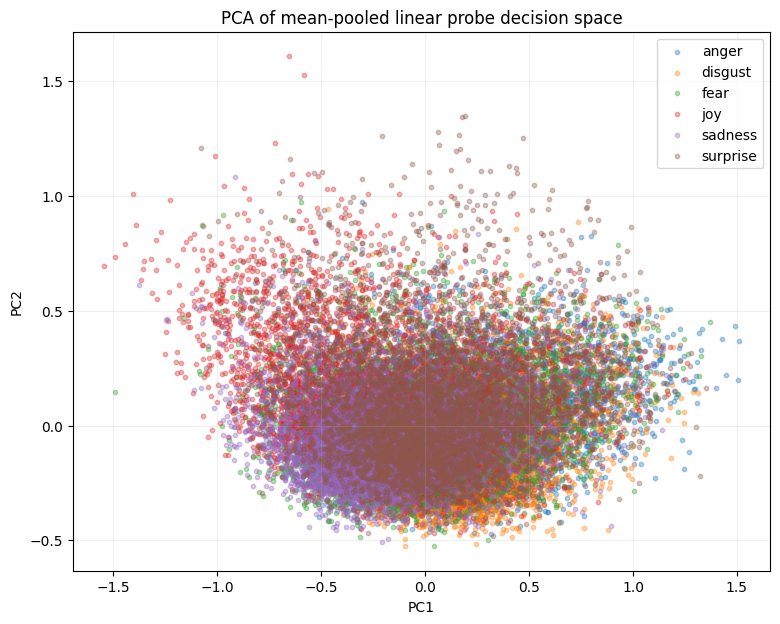


PCA of mean-pooled linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.6332 0.2483]


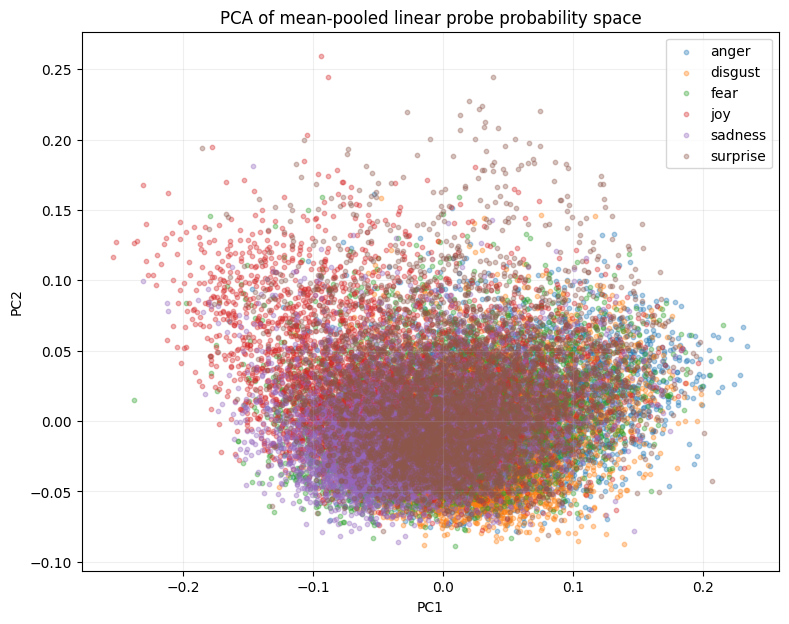


Emotion centroids in mean-pooled linear probe decision space
Probe space shape: (30000, 6)
Explained variance ratio: [0.6659 0.2457]


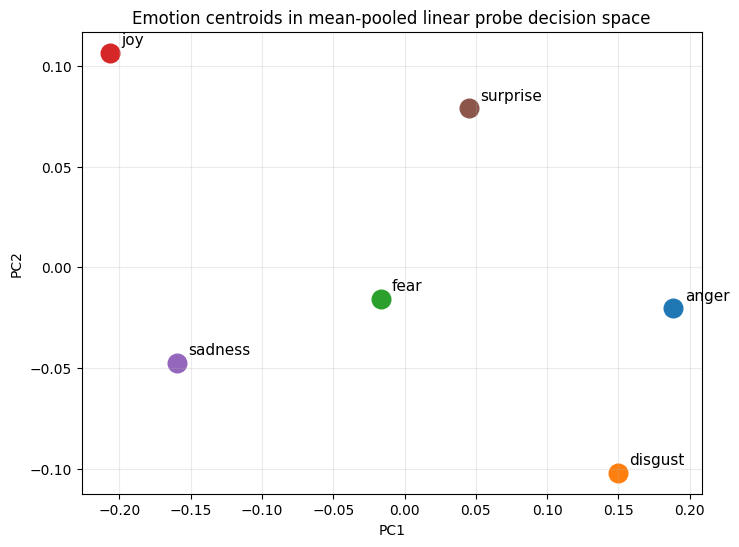


Emotion centroids in mean-pooled linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.6332 0.2483]


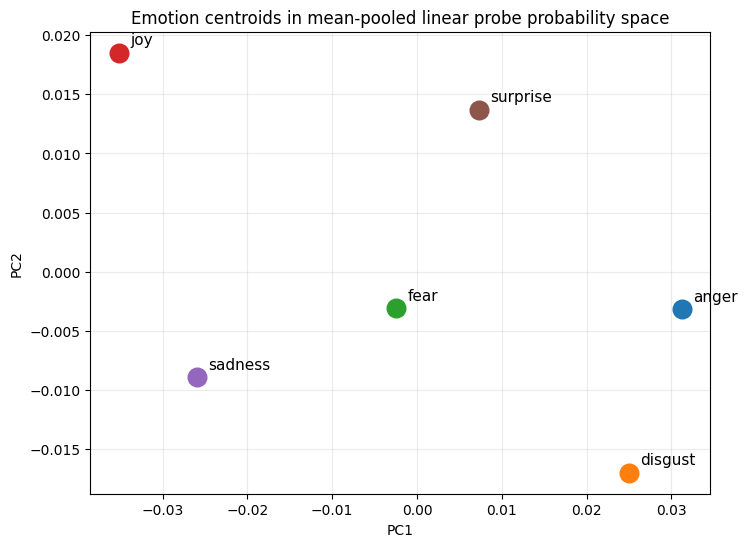


KDE contours of mean-pooled linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.6332 0.2483]


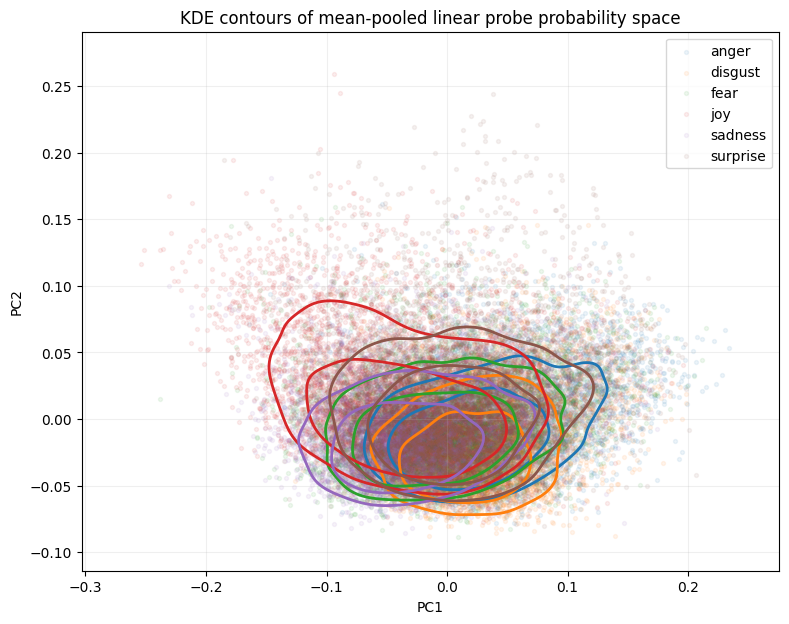


PCA of CLS linear probe decision space
Probe space shape: (30000, 6)
Explained variance ratio: [0.7753 0.1526]


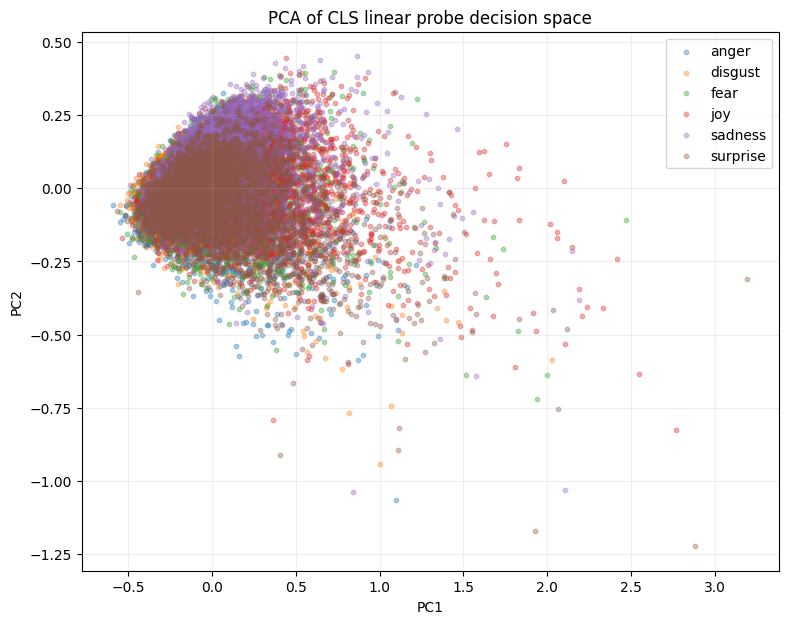


PCA of CLS linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.7478 0.1614]


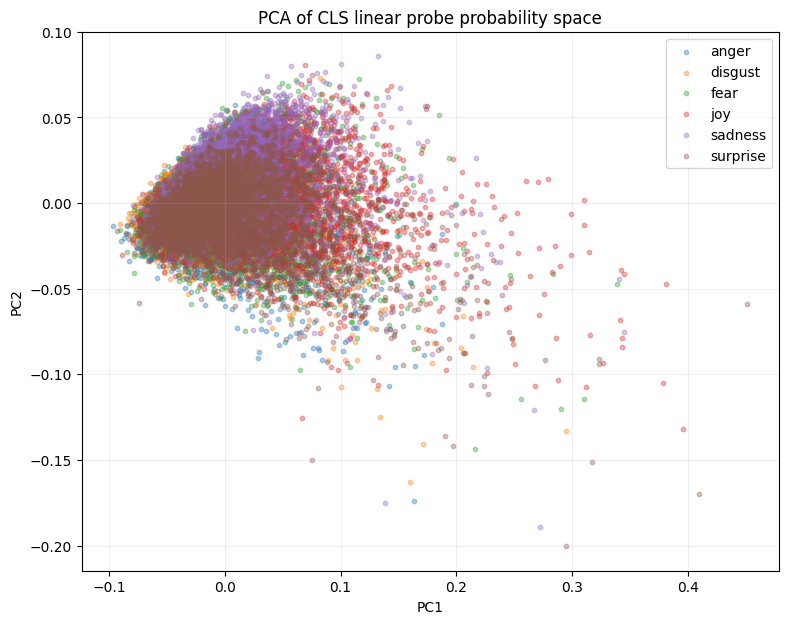


Emotion centroids in CLS linear probe decision space
Probe space shape: (30000, 6)
Explained variance ratio: [0.7753 0.1526]


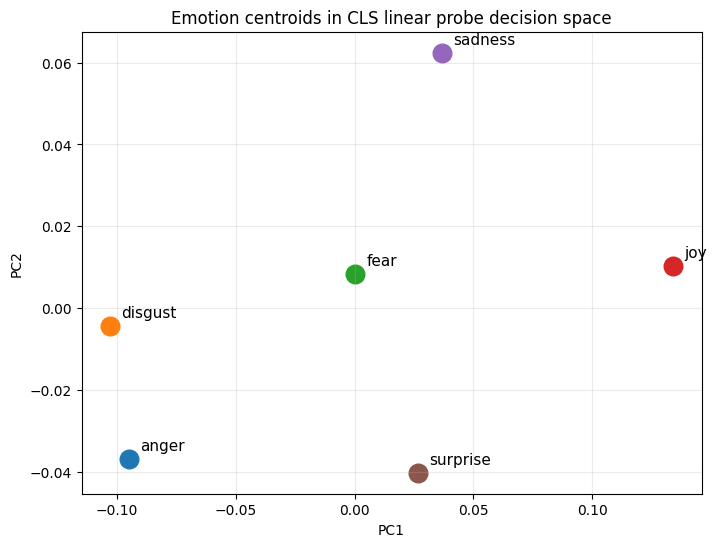


Emotion centroids in CLS linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.7478 0.1614]


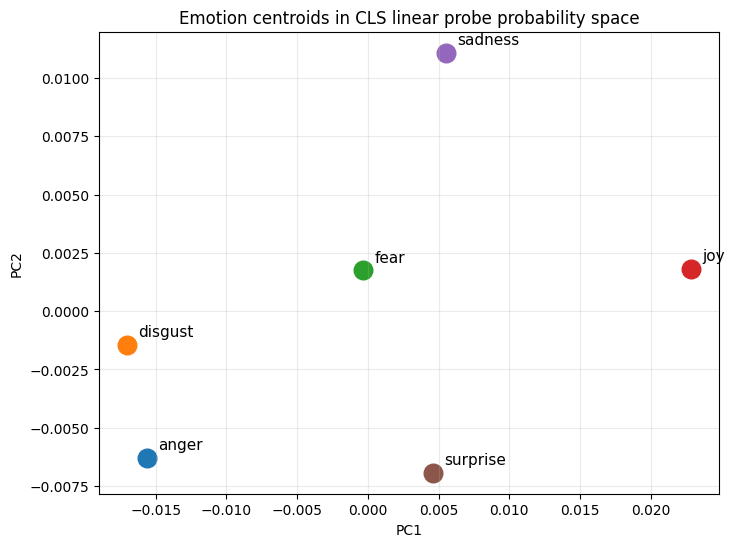


KDE contours of CLS linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.7478 0.1614]


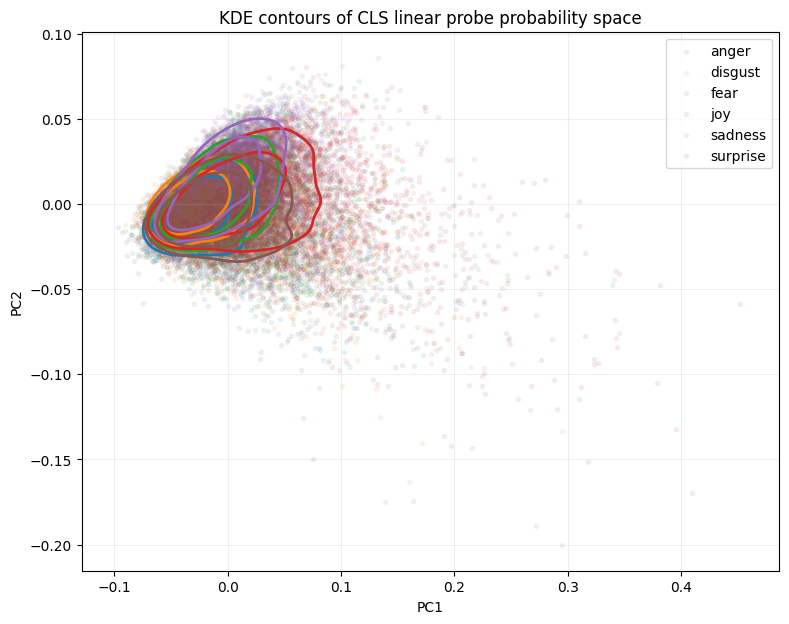

In [16]:
# probe training

mean_probe = train_probe(mean_embeddings_norm, labels, "Mean-pooled")
cls_probe = train_probe(cls_embeddings_norm, labels, "CLS")

# probe visualization

plot_probe_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "PCA of mean-pooled linear probe decision space",
    use_probabilities=False
)

# 2. PCA of probability space (all points)
plot_probe_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "PCA of mean-pooled linear probe probability space",
    use_probabilities=True
)

# 3. Centroids in decision space
plot_probe_centroids_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in mean-pooled linear probe decision space",
    use_probabilities=False
)

# 4. Centroids in probability space
plot_probe_centroids_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in mean-pooled linear probe probability space",
    use_probabilities=True
)

# 5. Paper-style KDE contours in probability space
plot_probe_kde_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "KDE contours of mean-pooled linear probe probability space",
    use_probabilities=True
)

##### CLS!!!!!

# probe visualization

plot_probe_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "PCA of CLS linear probe decision space",
    use_probabilities=False
)

# 2. PCA of probability space (all points)
plot_probe_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "PCA of CLS linear probe probability space",
    use_probabilities=True
)

# 3. Centroids in decision space
plot_probe_centroids_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in CLS linear probe decision space",
    use_probabilities=False
)

# 4. Centroids in probability space
plot_probe_centroids_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in CLS linear probe probability space",
    use_probabilities=True
)

# 5. Paper-style KDE contours in probability space
plot_probe_kde_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "KDE contours of CLS linear probe probability space",
    use_probabilities=True
)



Cosine similarity between mean-pooled probe weight vectors
          anger  disgust   fear    joy  sadness  surprise
anger     1.000    0.389 -0.092 -0.597   -0.580    -0.079
disgust   0.389    1.000 -0.267 -0.675   -0.395    -0.180
fear     -0.092   -0.267  1.000 -0.302    0.397    -0.184
joy      -0.597   -0.675 -0.302  1.000    0.136     0.153
sadness  -0.580   -0.395  0.397  0.136    1.000    -0.510
surprise -0.079   -0.180 -0.184  0.153   -0.510     1.000


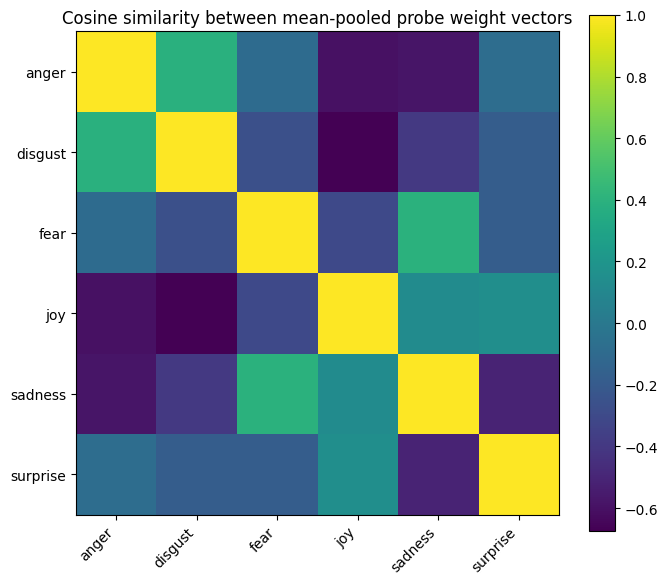


PCA of mean-pooled probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.4105 0.2917]


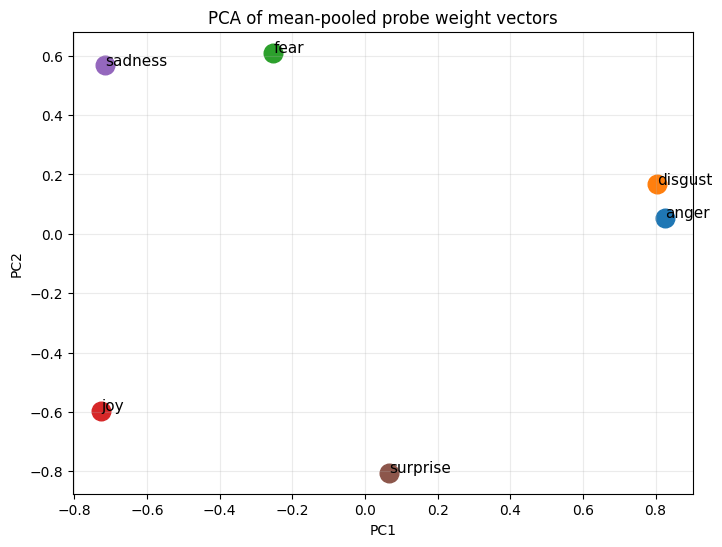


3D PCA of mean-pooled probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.4105 0.2917 0.1536]

3D PCA coordinates (per emotion):
    PC1     PC2     PC3  emotion
 0.8251  0.0546  0.0810    anger
 0.8039  0.1676 -0.4705  disgust
-0.2528  0.6101  0.5787     fear
-0.7267 -0.5962 -0.3347      joy
-0.7147  0.5686 -0.2629  sadness
 0.0652 -0.8047  0.4084 surprise

Desmos-friendly format:
anger: (0.8251, 0.0546, 0.0810)
disgust: (0.8039, 0.1676, -0.4705)
fear: (-0.2528, 0.6101, 0.5787)
joy: (-0.7267, -0.5962, -0.3347)
sadness: (-0.7147, 0.5686, -0.2629)
surprise: (0.0652, -0.8047, 0.4084)


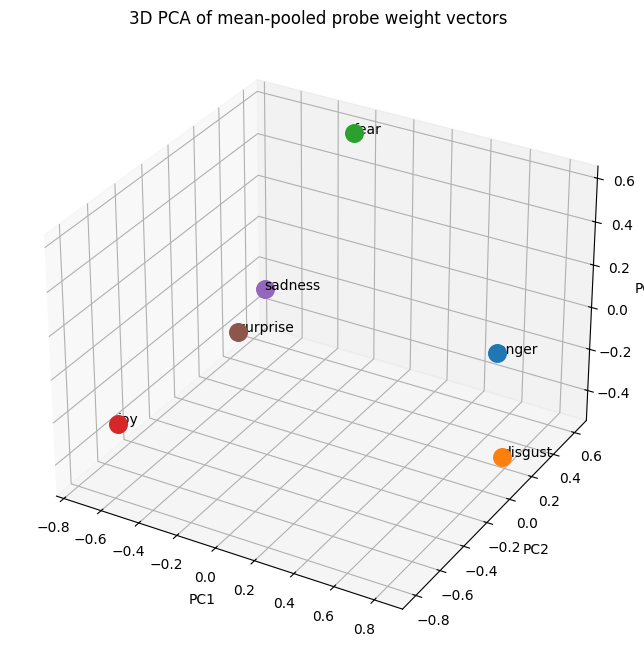


Mean-pooled probe weights vs mean-pooled class centroids
Combined shape: (12, 768)
Explained variance ratio: [0.3397 0.2717]


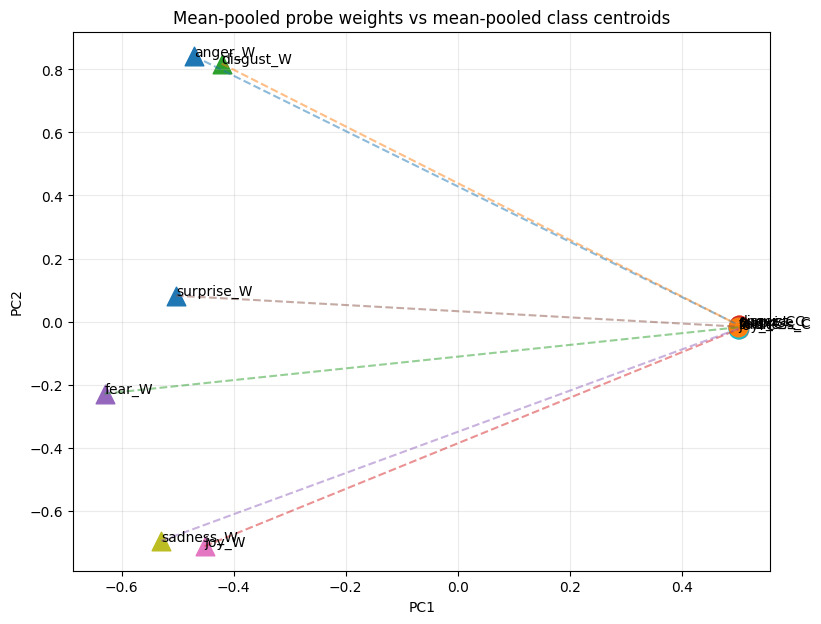


Cosine similarity between CLS probe weight vectors
          anger  disgust   fear    joy  sadness  surprise
anger     1.000    0.312  0.008 -0.655   -0.589     0.076
disgust   0.312    1.000 -0.341 -0.620   -0.374    -0.166
fear      0.008   -0.341  1.000 -0.280    0.361    -0.221
joy      -0.655   -0.620 -0.280  1.000    0.196     0.096
sadness  -0.589   -0.374  0.361  0.196    1.000    -0.607
surprise  0.076   -0.166 -0.221  0.096   -0.607     1.000


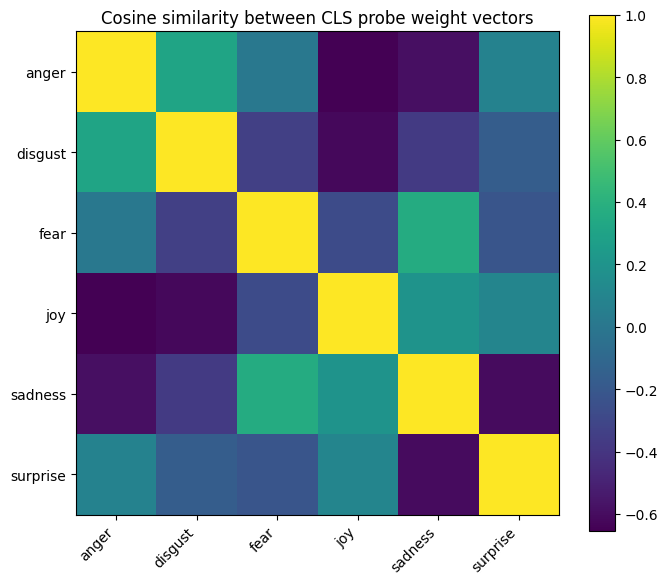


PCA of CLS probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.4127 0.2853]


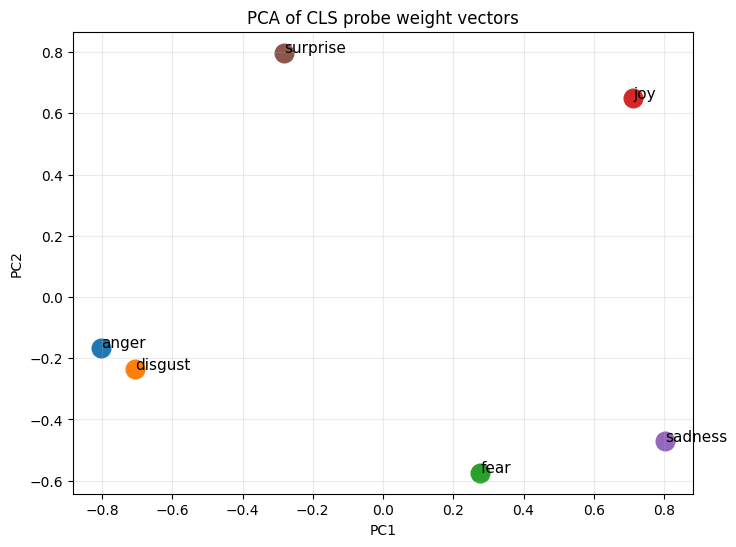


3D PCA of CLS probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.4127 0.2853 0.1799]

3D PCA coordinates (per emotion):
    PC1     PC2     PC3  emotion
-0.8027 -0.1656  0.2328    anger
-0.7068 -0.2363 -0.6708  disgust
 0.2775 -0.5738  0.5883     fear
 0.7115  0.6497 -0.2361      joy
 0.8020 -0.4717 -0.2384  sadness
-0.2815  0.7977  0.3242 surprise

Desmos-friendly format:
anger: (-0.8027, -0.1656, 0.2328)
disgust: (-0.7068, -0.2363, -0.6708)
fear: (0.2775, -0.5738, 0.5883)
joy: (0.7115, 0.6497, -0.2361)
sadness: (0.8020, -0.4717, -0.2384)
surprise: (-0.2815, 0.7977, 0.3242)


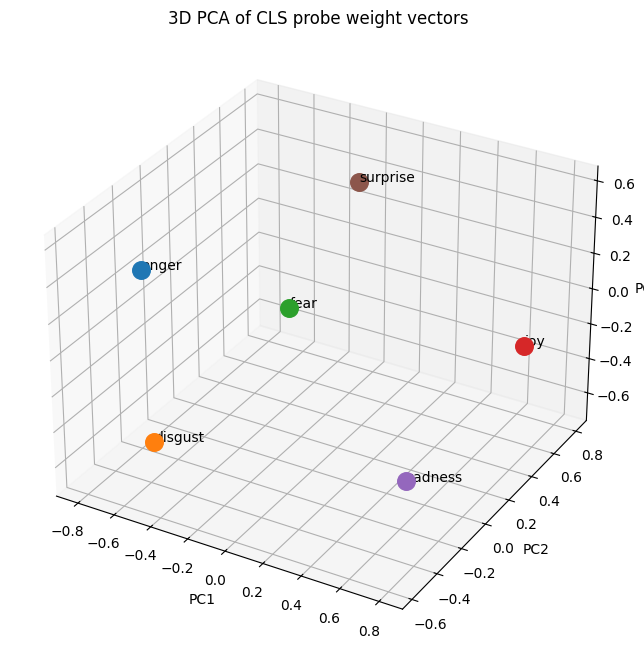


CLS probe weights vs CLS class centroids
Combined shape: (12, 768)
Explained variance ratio: [0.3415 0.2725]


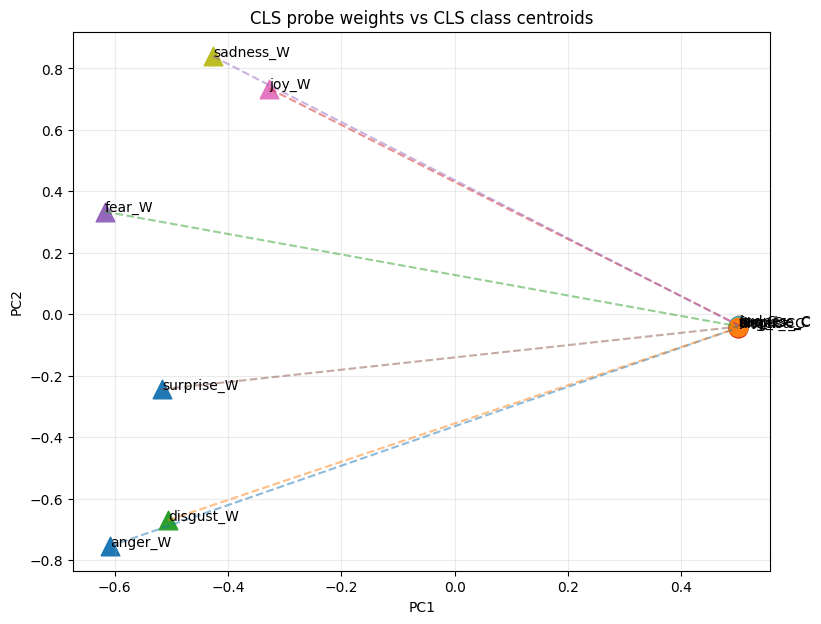

(array([[-0.60827798, -0.7549472 ],
        [-0.50568825, -0.67038556],
        [-0.61747055,  0.33412519],
        [-0.32679427,  0.7343762 ],
        [-0.42650712,  0.83987657],
        [-0.51645092, -0.24384433]]),
 array([[ 0.49970144, -0.04383004],
        [ 0.50009283, -0.04380406],
        [ 0.49996587, -0.03924337],
        [ 0.50090364, -0.03546553],
        [ 0.5004179 , -0.03661021],
        [ 0.50010741, -0.04024766]]),
 PCA(n_components=2, random_state=42))

In [17]:

# Probe weight analysis

class_order = list(mean_probe.classes_)

# Mean-pooled probe weights
plot_probe_weight_cosine_similarity(
    mean_probe,
    class_order,
    "Cosine similarity between mean-pooled probe weight vectors"
)

plot_probe_weights_pca_2d(
    mean_probe,
    class_order,
    "PCA of mean-pooled probe weight vectors"
)

plot_probe_weights_pca_3d(
    mean_probe,
    class_order,
    "3D PCA of mean-pooled probe weight vectors"
)

plot_probe_weights_vs_centroids_pca_2d(
    mean_probe,
    mean_centroids,
    class_order,
    "Mean-pooled probe weights vs mean-pooled class centroids"
)


# CLS probe weights
plot_probe_weight_cosine_similarity(
    cls_probe,
    class_order,
    "Cosine similarity between CLS probe weight vectors"
)

plot_probe_weights_pca_2d(
    cls_probe,
    class_order,
    "PCA of CLS probe weight vectors"
)

plot_probe_weights_pca_3d(
    cls_probe,
    class_order,
    "3D PCA of CLS probe weight vectors"
)

plot_probe_weights_vs_centroids_pca_2d(
    cls_probe,
    cls_centroids,
    class_order,
    "CLS probe weights vs CLS class centroids"
)

In [18]:
# example prediction and t-sne


print("\n--- Example predictions with mean-pooled probe ---")
predict_examples(example_texts, tokenizer, model, device, mean_probe, use_mean=True)

print("\n--- Example predictions with CLS probe ---")
predict_examples(example_texts, tokenizer, model, device, cls_probe, use_mean=False)

X_tsne_input = mean_embeddings_norm
y_tsne = df["emotion"].values


--- Example predictions with mean-pooled probe ---


Encoding: 100%|██████████| 1/1 [00:00<00:00,  1.74it/s]



TEXT: I am so happy and excited about this!
Predicted: joy
Top-3: [('joy', 0.25), ('sadness', 0.195), ('surprise', 0.195)]

TEXT: This is disgusting and makes me sick.
Predicted: disgust
Top-3: [('disgust', 0.18), ('sadness', 0.18), ('fear', 0.175)]

TEXT: I am terrified something bad will happen.
Predicted: sadness
Top-3: [('sadness', 0.209), ('fear', 0.188), ('joy', 0.168)]

TEXT: I miss you so much and feel empty.
Predicted: sadness
Top-3: [('sadness', 0.259), ('joy', 0.21), ('fear', 0.169)]

TEXT: What a wonderful surprise!
Predicted: surprise
Top-3: [('surprise', 0.299), ('joy', 0.256), ('fear', 0.151)]

TEXT: I am furious and cannot stand this anymore.
Predicted: sadness
Top-3: [('sadness', 0.212), ('fear', 0.181), ('anger', 0.156)]

--- Example predictions with CLS probe ---


Encoding: 100%|██████████| 1/1 [00:00<00:00, 36.54it/s]


TEXT: I am so happy and excited about this!
Predicted: joy
Top-3: [('joy', 0.225), ('surprise', 0.206), ('fear', 0.164)]

TEXT: This is disgusting and makes me sick.
Predicted: fear
Top-3: [('fear', 0.173), ('sadness', 0.171), ('surprise', 0.171)]

TEXT: I am terrified something bad will happen.
Predicted: sadness
Top-3: [('sadness', 0.186), ('fear', 0.179), ('surprise', 0.173)]

TEXT: I miss you so much and feel empty.
Predicted: joy
Top-3: [('joy', 0.227), ('sadness', 0.218), ('fear', 0.166)]

TEXT: What a wonderful surprise!
Predicted: joy
Top-3: [('joy', 0.283), ('surprise', 0.246), ('fear', 0.153)]

TEXT: I am furious and cannot stand this anymore.
Predicted: sadness
Top-3: [('sadness', 0.192), ('fear', 0.176), ('joy', 0.171)]


In [19]:
from datasets import load_dataset
import pandas as pd

target_emotions = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]
random_state = 42

# =====================================================
# 1. LOAD BRIGHTER
# =====================================================
dfs = []

for split in ["train", "dev", "test"]:
    ds = load_dataset(
        "brighter-dataset/BRIGHTER-emotion-categories",
        "eng",
        split=split
    )
    df_part = ds.to_pandas()
    dfs.append(df_part)

brighter_df = pd.concat(dfs, ignore_index=True)
brighter_df["text"] = brighter_df["text"].astype(str)

# ensure all emotion columns exist + clean
for col in target_emotions:
    if col not in brighter_df.columns:
        brighter_df[col] = 0
    brighter_df[col] = brighter_df[col].fillna(0).astype(int)

# keep only single-label
brighter_df["n_active"] = brighter_df[target_emotions].sum(axis=1)
brighter_df = brighter_df[brighter_df["n_active"] == 1].copy()

# convert to single label
brighter_df["emotion"] = brighter_df[target_emotions].idxmax(axis=1)

brighter_df = brighter_df[["text", "emotion"]]

print("\nBRIGHTER distribution:")
print(brighter_df["emotion"].value_counts())


# # =====================================================
# # 2. LOAD GOEMOTIONS (your CSV)
# # =====================================================
# go_df = pd.read_csv("goemotions_english.csv")

# go_df["text"] = go_df["text"].astype(str)
# go_df["emotion"] = go_df["emotion"].astype(str)

# # keep only target emotions (important!)
# go_df = go_df[go_df["emotion"].isin(target_emotions)]

# print("\nGoEmotions distribution:")
# print(go_df["emotion"].value_counts())


# =====================================================
# 2.1 LOAD XED (your CSV)
# =====================================================
xed_df = pd.read_csv("xed_english.csv")

xed_df["text"] = xed_df["text"].astype(str)
xed_df["emotion"] = xed_df["emotion"].astype(str)

# keep only target emotions (important!)
xed_df = xed_df[xed_df["emotion"].isin(target_emotions)]

print("\XED distribution:")
print(xed_df["emotion"].value_counts())


# =====================================================
# 3. COMBINE
# =====================================================
comb_df = pd.concat([brighter_df, xed_df], ignore_index=True)

print("\nCombined distribution BEFORE balancing:")
print(comb_df["emotion"].value_counts())


# =====================================================
# 4. BALANCE
# =====================================================
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []

for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced rows:", len(comb_df))
print("\nBalanced distribution:")
print(comb_df["emotion"].value_counts())


# =====================================================
# 5. FINAL OUTPUT
# =====================================================
xed_texts = comb_df["text"].tolist()
xed_labels = comb_df["emotion"].tolist()


xed_mean_embeddings, xed_cls_embeddings = encode_texts(
    xed_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

xed_mean_embeddings_norm = normalize(xed_mean_embeddings, norm="l2")
xed_cls_embeddings_norm = normalize(xed_cls_embeddings, norm="l2")

print("\nXED mean embeddings shape:", xed_mean_embeddings_norm.shape)
print("XED CLS embeddings shape:", xed_cls_embeddings_norm.shape)

print("\nMean probe classes:", mean_probe.classes_)
print("CLS probe classes:", cls_probe.classes_)

class_order = list(mean_probe.classes_)

# Split df into calibration and test
mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    xed_mean_embeddings_norm,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    xed_cls_embeddings_norm,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)



print("\nCalibration set size:", len(y_calib))
print("Test set size:", len(y_test))


# Evaluation stats
def evaluate_probe_on_single_label(embeddings, probe, gold_labels, class_order, name="Probe"):
    preds = probe.predict(embeddings)
    probs = probe.predict_proba(embeddings)

    print(f"\n=== {name} on XED test ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))
    
    
    # Top-3 accuracy
    
    top_k = 3

    # get indices of top-3 predictions per sample
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]

    # map labels to indices
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in gold_labels])

    # check if gold label is in top-k
    top_k_correct = [
        gold_idx[i] in top_k_preds[i]
        for i in range(len(gold_idx))
    ]

    top_k_acc = np.mean(top_k_correct)

    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    confidence_df = pd.DataFrame({
        "gold": gold_labels,
        "pred": preds,
        "confidence": pred_conf
    })

    per_class_conf = (
        confidence_df.groupby("gold")["confidence"]
        .agg(["mean", "std", "count"])
        .round(4)
        .rename_axis("emotion")
        .reset_index()
    )

    print("\nPer-class confidence stats:")
    print(per_class_conf.to_string(index=False))

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df,
        "confidence_stats": per_class_conf,
    }


# Baseline: uncalibrated
mean_base_results = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled mBERT (uncalibrated)"
)


BRIGHTER distribution:
emotion
joy         1350
fear        1134
sadness      401
surprise     335
anger        198
Name: count, dtype: int64
\XED distribution:
emotion
anger       2391
joy         1721
fear        1529
sadness     1527
surprise    1429
disgust     1413
Name: count, dtype: int64

Combined distribution BEFORE balancing:
emotion
joy         3071
fear        2663
anger       2589
sadness     1928
surprise    1764
disgust     1413
Name: count, dtype: int64

Balanced rows: 8478

Balanced distribution:
emotion
anger       1413
surprise    1413
fear        1413
joy         1413
sadness     1413
disgust     1413
Name: count, dtype: int64


Encoding: 100%|██████████| 265/265 [00:51<00:00,  5.16it/s]



XED mean embeddings shape: (8478, 768)
XED CLS embeddings shape: (8478, 768)

Mean probe classes: ['anger' 'disgust' 'fear' 'joy' 'sadness' 'surprise']
CLS probe classes: ['anger' 'disgust' 'fear' 'joy' 'sadness' 'surprise']

Calibration set size: 4239
Test set size: 4239

=== Mean-pooled mBERT (uncalibrated) on XED test ===
Accuracy: 0.2744
Balanced accuracy: 0.2744
Macro F1: 0.2551
Weighted F1: 0.2551
Log loss: 1.737
Top-3 accuracy: 0.6617

Classification report:
              precision    recall  f1-score   support

       anger      0.248     0.265     0.256       706
     disgust      0.224     0.123     0.159       706
        fear      0.371     0.092     0.147       707
         joy      0.379     0.232     0.288       707
     sadness      0.320     0.383     0.349       707
    surprise      0.237     0.551     0.331       706

    accuracy                          0.274      4239
   macro avg      0.297     0.274     0.255      4239
weighted avg      0.297     0.274     0.2

In [20]:
# =====================================================
# HUMAN-LABEL FINE-TUNED PROBE
# =====================================================

from sklearn.linear_model import LogisticRegression

def train_eval_human_probe(X_calib, X_test, y_calib, y_test, class_order, name):
    human_probe = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    human_probe.fit(X_calib, y_calib)

    preds = human_probe.predict(X_test)
    probs = human_probe.predict_proba(X_test)

    print(f"\n=== {name}: probe trained on human calibration data ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    top_k = 3
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in y_test])
    top_k_acc = np.mean([gold_idx[i] in top_k_preds[i] for i in range(len(gold_idx))])
    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": human_probe,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


mean_human_probe_results = train_eval_human_probe(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled"
)

cls_human_probe_results = train_eval_human_probe(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    class_order,
    name="CLS"
)


=== Mean-pooled: probe trained on human calibration data ===
Accuracy: 0.3251
Balanced accuracy: 0.3251
Macro F1: 0.3174
Weighted F1: 0.3174
Log loss: 1.7452
Top-3 accuracy: 0.7082

Classification report:
              precision    recall  f1-score   support

       anger      0.258     0.364     0.302       706
     disgust      0.387     0.181     0.247       706
        fear      0.261     0.474     0.336       707
         joy      0.524     0.170     0.256       707
     sadness      0.349     0.324     0.336       707
    surprise      0.416     0.438     0.427       706

    accuracy                          0.325      4239
   macro avg      0.366     0.325     0.317      4239
weighted avg      0.366     0.325     0.317      4239

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       257       61   151   14      117       106
disgust     170      128   209   28       92        79
fear        141       41   335   12       81        97
joy         1

In [21]:
from sklearn.linear_model import LogisticRegression

# =====================================================
# 6D EMOTION SUBSPACE CLASSIFIER
# =====================================================

def project_to_probe_subspace(X, probe, use_bias=False):
    W = probe.coef_.copy()
    Z = X @ W.T

    if use_bias:
        Z = Z + probe.intercept_

    return Z


def train_eval_6d_classifier(X_calib, X_test, y_calib, y_test, probe, class_order, name, use_bias=False):
    Z_calib = project_to_probe_subspace(X_calib, probe, use_bias=use_bias)
    Z_test = project_to_probe_subspace(X_test, probe, use_bias=use_bias)

    clf_6d = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    clf_6d.fit(Z_calib, y_calib)

    preds = clf_6d.predict(Z_test)
    probs = clf_6d.predict_proba(Z_test)

    print(f"\n=== {name}: Logistic Regression on 6D probe subspace ===")
    print("6D train shape:", Z_calib.shape)
    print("6D test shape:", Z_test.shape)
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": clf_6d,
        "Z_calib": Z_calib,
        "Z_test": Z_test,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


mean_6d_results = train_eval_6d_classifier(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    mean_probe,
    class_order,
    name="Mean-pooled"
)

cls_6d_results = train_eval_6d_classifier(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    cls_probe,
    class_order,
    name="CLS"
)


=== Mean-pooled: Logistic Regression on 6D probe subspace ===
6D train shape: (4239, 6)
6D test shape: (4239, 6)
Accuracy: 0.3557
Balanced accuracy: 0.3557
Macro F1: 0.3499
Weighted F1: 0.35
Log loss: 1.6041

Classification report:
              precision    recall  f1-score   support

       anger      0.285     0.193     0.230       706
     disgust      0.336     0.353     0.344       706
        fear      0.357     0.311     0.333       707
         joy      0.401     0.481     0.438       707
     sadness      0.364     0.446     0.401       707
    surprise      0.359     0.351     0.355       706

    accuracy                          0.356      4239
   macro avg      0.350     0.356     0.350      4239
weighted avg      0.350     0.356     0.350      4239

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       136      141    71  112      158        88
disgust      83      249    81  128       85        80
fear         65       88   220   79      

In [22]:
mean_6d_human_probe_results = train_eval_6d_classifier(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    mean_human_probe_results["model"],
    class_order,
    name="Mean-pooled human-probe 6D"
)

cls_6d_human_probe_results = train_eval_6d_classifier(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    cls_human_probe_results["model"],
    class_order,
    name="CLS human-probe 6D"
)


=== Mean-pooled human-probe 6D: Logistic Regression on 6D probe subspace ===
6D train shape: (4239, 6)
6D test shape: (4239, 6)
Accuracy: 0.4159
Balanced accuracy: 0.4159
Macro F1: 0.4106
Weighted F1: 0.4106
Log loss: 1.5271

Classification report:
              precision    recall  f1-score   support

       anger      0.368     0.282     0.319       706
     disgust      0.394     0.435     0.413       706
        fear      0.385     0.294     0.334       707
         joy      0.521     0.604     0.559       707
     sadness      0.375     0.430     0.401       707
    surprise      0.425     0.450     0.437       706

    accuracy                          0.416      4239
   macro avg      0.411     0.416     0.411      4239
weighted avg      0.411     0.416     0.411      4239

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       199      137    76   37      151       106
disgust      99      307    57   49       99        95
fear         96       88

In [23]:
# =====================================================
# LABEL DISAGREEMENT / ERROR INSPECTION
# =====================================================

# Recreate split with indices so we can recover the original texts
all_indices = np.arange(len(comb_df))

mean_idx_calib, mean_idx_test, _, _ = train_test_split(
    all_indices,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)

test_texts = comb_df.iloc[mean_idx_test]["text"].tolist()
test_gold = np.array(y_test)

def inspect_strong_disagreements(X_test, probe, test_texts, gold_labels, class_order, n=30, name="Probe"):
    probs = probe.predict_proba(X_test)
    preds = probe.predict(X_test)

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    rows = []

    for i in range(len(gold_labels)):
        if preds[i] != gold_labels[i]:
            top3_idx = np.argsort(probs[i])[::-1][:3]
            top3 = [(class_order[j], round(float(probs[i, j]), 3)) for j in top3_idx]

            rows.append({
                "text": test_texts[i],
                "gold": gold_labels[i],
                "pred": preds[i],
                "confidence": pred_conf[i],
                "top3": top3
            })

    err_df = pd.DataFrame(rows).sort_values("confidence", ascending=False)

    print(f"\n=== Strongest disagreements: {name} ===")
    print("Total errors:", len(err_df))

    for _, row in err_df.head(n).iterrows():
        print("\nTEXT:", row["text"])
        print("Gold:", row["gold"])
        print("Pred:", row["pred"])
        print("Confidence:", round(row["confidence"], 4))
        print("Top-3:", row["top3"])

    return err_df


mean_error_df = inspect_strong_disagreements(
    mean_X_test,
    mean_probe,
    test_texts,
    test_gold,
    class_order,
    n=30,
    name="Mean-pooled probe"
)

cls_error_df = inspect_strong_disagreements(
    cls_X_test,
    cls_probe,
    test_texts,
    test_gold,
    class_order,
    n=30,
    name="CLS probe"
)


=== Strongest disagreements: Mean-pooled probe ===
Total errors: 3076

TEXT: Happy birthday .
Gold: joy
Pred: surprise
Confidence: 0.5285
Top-3: [('surprise', 0.528), ('joy', 0.206), ('anger', 0.083)]

TEXT: How tragic .
Gold: sadness
Pred: surprise
Confidence: 0.385
Top-3: [('surprise', 0.385), ('anger', 0.168), ('fear', 0.141)]

TEXT: Good morning .
Gold: joy
Pred: surprise
Confidence: 0.3431
Top-3: [('surprise', 0.343), ('joy', 0.275), ('fear', 0.117)]

TEXT: Out .
Gold: anger
Pred: surprise
Confidence: 0.341
Top-3: [('surprise', 0.341), ('anger', 0.215), ('fear', 0.144)]

TEXT: Pervert .
Gold: disgust
Pred: surprise
Confidence: 0.3323
Top-3: [('surprise', 0.332), ('anger', 0.201), ('joy', 0.16)]

TEXT: Assembly completed .
Gold: joy
Pred: surprise
Confidence: 0.3306
Top-3: [('surprise', 0.331), ('joy', 0.203), ('fear', 0.158)]

TEXT: Him !
Gold: disgust
Pred: surprise
Confidence: 0.3305
Top-3: [('surprise', 0.33), ('anger', 0.215), ('fear', 0.138)]

TEXT: Gone .
Gold: sadness
Pred

In [24]:

# Projection classifier: cosine to probe weights

mean_weight_preds, mean_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_weight_results = evaluate_simple_classifier(
    y_test,
    mean_weight_preds,
    mean_weight_scores,
    class_order,
    name="Mean-pooled XLM-R (cosine to probe weights)"
)

cls_weight_preds, cls_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_weight_results = evaluate_simple_classifier(
    y_test,
    cls_weight_preds,
    cls_weight_scores,
    class_order,
    name="CLS XLM-R (cosine to probe weights)"
)


# Prototype classifier: nearest centroid

mean_proto_preds, mean_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proto_preds,
    mean_proto_scores,
    class_order,
    name="Mean-pooled XLM-R (prototype classifier)"
)

cls_proto_preds, cls_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proto_preds,
    cls_proto_scores,
    class_order,
    name="CLS XLM-R (prototype classifier)"
)




=== Mean-pooled XLM-R (cosine to probe weights) on XED test ===
Accuracy: 0.2522
Balanced accuracy: 0.2522
Macro F1: 0.2084
Weighted F1: 0.2084
Log loss: 1.7876

Classification report:
              precision    recall  f1-score   support

       anger      0.288     0.088     0.135       706
     disgust      0.250     0.224     0.236       706
        fear      0.332     0.180     0.233       707
         joy      0.000     0.000     0.000       707
     sadness      0.339     0.294     0.315       707
    surprise      0.215     0.728     0.331       706

    accuracy                          0.252      4239
   macro avg      0.237     0.252     0.208      4239
weighted avg      0.237     0.252     0.208      4239

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        62       76    46    0      100       422
disgust      74      158    34    0       68       372
fear         35      128   127    0      100       317
joy          10      128    49   

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

Balanced accuracy: 0.2058
Macro F1: 0.1445
Weighted F1: 0.1445
Log loss: 1.7917

Classification report:
              precision    recall  f1-score   support

       anger      0.190     0.040     0.066       706
     disgust      0.235     0.068     0.105       706
        fear      0.340     0.072     0.119       707
         joy      0.370     0.042     0.076       707
     sadness      0.228     0.163     0.190       707
    surprise      0.190     0.850     0.311       706

    accuracy                          0.206      4239
   macro avg      0.259     0.206     0.145      4239
weighted avg      0.259     0.206     0.145      4239

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        28       22    12   12       48       584
disgust      61       48    22   13       44       518
fear         22       44    51    3      138       449
joy           9       48    23   30      113       484
sadness      14       21    22   17      115       518
surpr

In [25]:
### TEST

example_texts = [
    "I just got promoted at work, I can't believe it!",
    "This is absolutely disgusting, I feel sick.",
    "I'm really scared about what might happen tomorrow.",
    "I miss you so much, everything feels empty without you.",
    "Wow, I did not expect that at all!"
]

def print_topk_linear_predictions(
    texts,
    tokenizer,
    model,
    device,
    probe,
    class_order,
    use_mean=True,
    top_k=3
):
    # Encode
    mean_embs, cls_embs = encode_texts(
        texts,
        tokenizer,
        model,
        device,
        batch_size=8,
        max_length=MAX_LENGTH
    )

    if use_mean:
        X = normalize(mean_embs, norm="l2")
    else:
        X = normalize(cls_embs, norm="l2")

    # Get linear scores
    _, scores = predict_with_linear_scores(
        X,
        probe,
        class_order,
        normalize_inputs=False
    )

    print("\n=== Top-k predictions (linear scores x·w + b) ===\n")

    for i, text in enumerate(texts):
        score_vec = scores[i]

        # sort descending
        top_indices = np.argsort(score_vec)[::-1][:top_k]

        print(f"Text: {text}")
        for rank, idx in enumerate(top_indices, 1):
            emotion = class_order[idx]
            score = score_vec[idx]
            print(f"  {rank}. {emotion:10s} | score = {score:.4f}")
        print()
        
    _, scores = predict_with_weight_cosine(
        X,
        probe,
        class_order
    )

    print("\n=== Top-k predictions (just linear scores x·w) ===\n")

    for i, text in enumerate(texts):
        score_vec = scores[i]

        # sort descending
        top_indices = np.argsort(score_vec)[::-1][:top_k]

        print(f"Text: {text}")
        for rank, idx in enumerate(top_indices, 1):
            emotion = class_order[idx]
            score = score_vec[idx]
            print(f"  {rank}. {emotion:10s} | score = {score:.4f}")
        print()
        
print_topk_linear_predictions(
    example_texts,
    tokenizer,
    model,
    device,
    mean_probe,
    class_order,
    use_mean=True
)

Encoding: 100%|██████████| 1/1 [00:00<00:00,  1.19it/s]


=== Top-k predictions (linear scores x·w + b) ===

Text: I just got promoted at work, I can't believe it!
  1. sadness    | score = 0.2246
  2. fear       | score = 0.1372
  3. joy        | score = 0.0390

Text: This is absolutely disgusting, I feel sick.
  1. sadness    | score = 0.1422
  2. fear       | score = 0.0842
  3. surprise   | score = 0.0039

Text: I'm really scared about what might happen tomorrow.
  1. sadness    | score = 0.2731
  2. fear       | score = 0.1500
  3. joy        | score = 0.0429

Text: I miss you so much, everything feels empty without you.
  1. sadness    | score = 0.4815
  2. joy        | score = 0.3047
  3. fear       | score = 0.0460

Text: Wow, I did not expect that at all!
  1. surprise   | score = 0.2977
  2. joy        | score = 0.1833
  3. fear       | score = 0.1465


=== Top-k predictions (just linear scores x·w) ===

Text: I just got promoted at work, I can't believe it!
  1. fear       | score = 0.0187
  2. sadness    | score = 0.0167
  3. sur

In [26]:
def compute_label_centroids(X, y, class_order):
    y = np.array(y)
    centroids = []
    for emotion in class_order:
        mask = y == emotion
        centroids.append(X[mask].mean(axis=0))
    return normalize(np.vstack(centroids), norm="l2")


# Human-labeled English centroids

mean_human_centroids = compute_label_centroids(
    mean_X_calib,
    y_calib,
    class_order
)

# CHINESE

In [27]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_chinese.csv", "xed_tw.csv", "brighter_chinese.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 5426

Original German class distribution:
emotion
anger       2144
joy         1732
sadness      830
surprise     311
disgust      208
fear         201
Name: count, dtype: int64

Balanced German rows: 1206

Balanced German class distribution:
emotion
anger       201
disgust     201
joy         201
fear        201
sadness     201
surprise    201
Name: count, dtype: int64


Encoding: 100%|██████████| 38/38 [00:15<00:00,  2.50it/s]


German mean embeddings shape: (1206, 768)
German CLS embeddings shape: (1206, 768)

German calibration set size: 603
German test set size: 603


In [28]:

# Helpers

def softmax_np(scores):
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)


def evaluate_probe_on_single_label(embeddings, probe, gold_labels, class_order, name="Probe"):
    preds = probe.predict(embeddings)
    probs = probe.predict_proba(embeddings)

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import numpy as np

def fit_bias_only(
    X_calib,
    y_calib,
    probe,
    class_order,
    l2_values=(0.0, 1e-4, 1e-3, 1e-2, 1e-1, 1.0),
    random_state=42,
):
    """
    Freeze probe weights W, tune L2 regularization, and learn only bias b.
    L2 is selected using an internal split of the calibration set.
    """
    W = probe.coef_.copy()
    old_b = probe.intercept_.copy()

    label_to_idx = {label: i for i, label in enumerate(class_order)}

    X_train, X_val, y_train, y_val = train_test_split(
        X_calib,
        y_calib,
        test_size=0.3,
        random_state=random_state,
        stratify=y_calib,
    )

    y_train_idx = np.array([label_to_idx[y] for y in y_train])

    def softmax_np(scores):
        scores = scores - scores.max(axis=1, keepdims=True)
        exp_scores = np.exp(scores)
        return exp_scores / exp_scores.sum(axis=1, keepdims=True)

    def fit_for_l2(l2):
        def objective(b):
            scores = X_train @ W.T + b
            probs = softmax_np(scores)

            nll = -np.mean(
                np.log(probs[np.arange(len(y_train_idx)), y_train_idx] + 1e-12)
            )

            penalty = l2 * np.sum((b - old_b) ** 2)

            return nll + penalty

        result = minimize(
            objective,
            x0=old_b,
            method="BFGS",
        )

        return result.x

    best_l2 = None
    best_f1 = -1
    best_b = None

    print("\nBias-only calibration L2 search:")

    for l2 in l2_values:
        candidate_b = fit_for_l2(l2)

        val_scores = X_val @ W.T + candidate_b
        val_pred_idx = np.argmax(val_scores, axis=1)
        val_preds = np.array([class_order[i] for i in val_pred_idx])

        val_f1 = f1_score(y_val, val_preds, average="macro")

        print(f"  l2={l2:<8} validation_macro_f1={val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_l2 = l2
            best_b = candidate_b

    print(f"Best l2: {best_l2} | validation_macro_f1={best_f1:.4f}")

    # Refit final bias on the full calibration set using best L2
    y_calib_idx = np.array([label_to_idx[y] for y in y_calib])

    def final_objective(b):
        scores = X_calib @ W.T + b
        probs = softmax_np(scores)

        nll = -np.mean(
            np.log(probs[np.arange(len(y_calib_idx)), y_calib_idx] + 1e-12)
        )

        penalty = best_l2 * np.sum((b - old_b) ** 2)

        return nll + penalty

    final_result = minimize(
        final_objective,
        x0=old_b,
        method="BFGS",
    )

    return final_result.x


def evaluate_fixed_weights_new_bias(X_test, y_test, probe, new_b, class_order, name):
    W = probe.coef_.copy()
    scores = X_test @ W.T + new_b
    probs = softmax_np(scores)

    pred_idx = np.argmax(probs, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


def compute_label_centroids(X, y, class_order):
    y = np.array(y)
    centroids = []
    for emotion in class_order:
        mask = y == emotion
        centroids.append(X[mask].mean(axis=0))
    return normalize(np.vstack(centroids), norm="l2")


def fit_procrustes_from_centroids(X_calib, y_calib, target_centroids, class_order):
    """
    Learns an orthogonal rotation from German calibration centroids
    to English weak-label centroids.
    """
    source_centroids = compute_label_centroids(X_calib, y_calib, class_order)

    R, scale = orthogonal_procrustes(source_centroids, target_centroids)

    print("\nProcrustes scale:", round(scale, 4))

    return R


def apply_rotation(X, R):
    return normalize(X @ R, norm="l2")

In [29]:
from sklearn.linear_model import LogisticRegression

def project_to_probe_subspace(X, probe):
    """
    Projects embeddings into the 6D English probe-weight emotion space:
        Z = X @ W.T
    """
    W = probe.coef_.copy()
    return X @ W.T


def evaluate_6d_logreg(Z_calib, Z_test, y_calib, y_test, class_order, name):
    clf_6d = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    clf_6d.fit(Z_calib, y_calib)

    preds = clf_6d.predict(Z_test)
    probs = clf_6d.predict_proba(Z_test)

    print(f"\n=== {name}: LogReg on 6D projected emotion space ===")
    print("6D train shape:", Z_calib.shape)
    print("6D test shape:", Z_test.shape)
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": clf_6d,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }

In [30]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.272
Balanced accuracy: 0.2727
Macro F1: 0.1942
Weighted F1: 0.1941
Log loss: 1.7287

Classification report:
              precision    recall  f1-score   support

       anger      0.208     0.980     0.343       100
     disgust      0.000     0.000     0.000       100
        fear      1.000     0.020     0.039       101
         joy      0.679     0.376     0.484       101
     sadness      0.000     0.000     0.000       101
    surprise      0.351     0.260     0.299       100

    accuracy                          0.272       603
   macro avg      0.373     0.273     0.194       603
weighted avg      0.374     0.272     0.194       603

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        98        0     0    2        0         0
disgust      81        0     0    3        0        16
fear         80        0     2    0        0        19
joy          58        0     0   38        0 

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 5.9988

Procrustes scale: 6.0002

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.3781
Balanced accuracy: 0.3778
Macro F1: 0.3446
Weighted F1: 0.3447
Log loss: 1.6559

Classification report:
              precision    recall  f1-score   support

       anger      0.603     0.350     0.443       100
     disgust      0.375     0.150     0.214       100
        fear      0.000     0.000     0.000       101
         joy      0.700     0.762     0.730       101
     sadness      0.237     0.574     0.335       101
    surprise      0.289     0.430     0.345       100

    accuracy                          0.378       603
   macro avg      0.367     0.378     0.345       603
weighted avg      0.367     0.378     0.345       603

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        35        2     0    3       53         7
disgust       7       15     0    7       40        31
fear          5       12     0    1  

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled Procrustes-aligned German (nearest English weak centroid) on XED test ===
Accuracy: 0.3184
Balanced accuracy: 0.3179
Macro F1: 0.2715
Weighted F1: 0.2718
Log loss: 1.7917

Classification report:
              precision    recall  f1-score   support

       anger      0.615     0.080     0.142       100
     disgust      0.400     0.080     0.133       100
        fear      0.000     0.000     0.000       101
         joy      0.785     0.614     0.689       101
     sadness      0.211     0.663     0.321       101
    surprise      0.272     0.470     0.344       100

    accuracy                          0.318       603
   macro avg      0.381     0.318     0.271       603
weighted avg      0.380     0.318     0.272       603

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         8        1     0    2       81         8
disgust       4        8     0    3       49        36
fear          0        3     0    1       47        50
joy    

# ESTONIAN

In [31]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_estonian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
# target_n = comb_df["emotion"].value_counts().min()
target_n = 20

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 674

Original German class distribution:
emotion
anger       205
fear        106
joy         105
surprise    102
sadness     101
disgust      55
Name: count, dtype: int64

Balanced German rows: 120

Balanced German class distribution:
emotion
fear        20
anger       20
disgust     20
joy         20
surprise    20
sadness     20
Name: count, dtype: int64


Encoding: 100%|██████████| 4/4 [00:00<00:00,  4.34it/s]


German mean embeddings shape: (120, 768)
German CLS embeddings shape: (120, 768)

German calibration set size: 60
German test set size: 60


In [32]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.25
Balanced accuracy: 0.25
Macro F1: 0.2009
Weighted F1: 0.2009
Log loss: 1.7488

Classification report:
              precision    recall  f1-score   support

       anger      0.286     0.400     0.333        10
     disgust      0.500     0.100     0.167        10
        fear      0.000     0.000     0.000        10
         joy      0.182     0.200     0.190        10
     sadness      1.000     0.100     0.182        10
    surprise      0.219     0.700     0.333        10

    accuracy                          0.250        60
   macro avg      0.364     0.250     0.201        60
weighted avg      0.364     0.250     0.201        60

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         4        0     0    1        0         5
disgust       4        1     0    1        0         4
fear          1        1     0    2        0         6
joy           2        0     0    2        0    

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 5.9984

Procrustes scale: 5.998

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.2167
Balanced accuracy: 0.2167
Macro F1: 0.1602
Weighted F1: 0.1602
Log loss: 2.1099

Classification report:
              precision    recall  f1-score   support

       anger      0.500     0.100     0.167        10
     disgust      0.227     0.500     0.312        10
        fear      1.000     0.100     0.182        10
         joy      0.200     0.600     0.300        10
     sadness      0.000     0.000     0.000        10
    surprise      0.000     0.000     0.000        10

    accuracy                          0.217        60
   macro avg      0.321     0.217     0.160        60
weighted avg      0.321     0.217     0.160        60

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         1        2     0    5        2         0
disgust       0        5     0    3        2         0
fear          0        3     1    6   

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

  l2=0.001    validation_macro_f1=0.6929
  l2=0.01     validation_macro_f1=0.6929
  l2=0.1      validation_macro_f1=0.6929
  l2=1.0      validation_macro_f1=0.5194
Best l2: 0.0 | validation_macro_f1=0.6929

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.2333
Balanced accuracy: 0.2333
Macro F1: 0.2112
Weighted F1: 0.2112
Log loss: 2.0907

Classification report:
              precision    recall  f1-score   support

       anger      0.250     0.100     0.143        10
     disgust      0.263     0.500     0.345        10
        fear      1.000     0.200     0.333        10
         joy      0.217     0.500     0.303        10
     sadness      0.000     0.000     0.000        10
    surprise      0.250     0.100     0.143        10

    accuracy                          0.233        60
   macro avg      0.330     0.233     0.211        60
weighted avg      0.330     0.233     0.211        60

Confusion matrix:
          anger  disgust  fear  joy  sadness  surp

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

# RUSSIAN

In [33]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_russian.csv", "brighter_russian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 4540

Original German class distribution:
emotion
anger       1043
joy         1015
fear         734
sadness      724
surprise     612
disgust      412
Name: count, dtype: int64

Balanced German rows: 2472

Balanced German class distribution:
emotion
fear        412
surprise    412
sadness     412
joy         412
anger       412
disgust     412
Name: count, dtype: int64


Encoding: 100%|██████████| 78/78 [00:14<00:00,  5.42it/s]


German mean embeddings shape: (2472, 768)
German CLS embeddings shape: (2472, 768)

German calibration set size: 1236
German test set size: 1236


In [34]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)


=== Mean-pooled English probe directly on German ===
Accuracy: 0.2727
Balanced accuracy: 0.2727
Macro F1: 0.2389
Weighted F1: 0.2389
Log loss: 1.7431

Classification report:
              precision    recall  f1-score   support

       anger      0.225     0.646     0.334       206
     disgust      0.627     0.204     0.308       206
        fear      0.214     0.073     0.109       206
         joy      0.266     0.121     0.167       206
     sadness      0.260     0.097     0.141       206
    surprise      0.302     0.495     0.375       206

    accuracy                          0.273      1236
   macro avg      0.316     0.273     0.239      1236
weighted avg      0.316     0.273     0.239      1236

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       133       12     3   16        4        38
disgust      93       42    18   13        9        31
fear         74        8    15   15       34        60
joy         104        0     4   25        1

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 5.9997

Procrustes scale: 5.9999

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.3487
Balanced accuracy: 0.3487
Macro F1: 0.3371
Weighted F1: 0.3371
Log loss: 1.6536

Classification report:
              precision    recall  f1-score   support

       anger      0.324     0.170     0.223       206
     disgust      0.246     0.684     0.362       206
        fear      0.440     0.107     0.172       206
         joy      0.493     0.481     0.486       206
     sadness      0.877     0.311     0.459       206
    surprise      0.303     0.340     0.320       206

    accuracy                          0.349      1236
   macro avg      0.447     0.349     0.337      1236
weighted avg      0.447     0.349     0.337      1236

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        35      102    14   23        0        32
disgust      27      141     1    7        0        30
fear         19      102    22   14  

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

  l2=0.0      validation_macro_f1=0.3816
  l2=0.0001   validation_macro_f1=0.3804
  l2=0.001    validation_macro_f1=0.3804
  l2=0.01     validation_macro_f1=0.3787
  l2=0.1      validation_macro_f1=0.3823
  l2=1.0      validation_macro_f1=0.3716
Best l2: 0.1 | validation_macro_f1=0.3823

Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.3068
  l2=0.0001   validation_macro_f1=0.3068
  l2=0.001    validation_macro_f1=0.3068
  l2=0.01     validation_macro_f1=0.2975
  l2=0.1      validation_macro_f1=0.2617
  l2=1.0      validation_macro_f1=0.2541
Best l2: 0.0 | validation_macro_f1=0.3068

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.3641
Balanced accuracy: 0.3641
Macro F1: 0.3592
Weighted F1: 0.3592
Log loss: 1.6524

Classification report:
              precision    recall  f1-score   support

       anger      0.306     0.199     0.241       206
     disgust      0.258     0.660     0.371       206
        fear      0.429     0.146     0.217 

# SWAHILI

In [35]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["brighter_swahili.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 3965

Original German class distribution:
emotion
surprise    1103
joy          951
sadness      675
anger        623
disgust      434
fear         179
Name: count, dtype: int64

Balanced German rows: 1074

Balanced German class distribution:
emotion
joy         179
fear        179
disgust     179
surprise    179
anger       179
sadness     179
Name: count, dtype: int64


Encoding: 100%|██████████| 34/34 [00:08<00:00,  4.19it/s]


German mean embeddings shape: (1074, 768)
German CLS embeddings shape: (1074, 768)

German calibration set size: 537
German test set size: 537


In [36]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.1806
Balanced accuracy: 0.1816
Macro F1: 0.0787
Weighted F1: 0.0783
Log loss: 1.8132

Classification report:
              precision    recall  f1-score   support

       anger      0.172     0.989     0.292        89
     disgust      0.429     0.034     0.062        89
        fear      0.000     0.000     0.000        90
         joy      1.000     0.011     0.022        90
     sadness      0.000     0.000     0.000        90
    surprise      0.312     0.056     0.095        89

    accuracy                          0.181       537
   macro avg      0.319     0.182     0.079       537
weighted avg      0.319     0.181     0.078       537

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        88        0     0    0        0         1
disgust      85        3     0    0        0         1
fear         87        1     0    0        0         2
joy          83        1     0    1        0

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 6.0002

Procrustes scale: 6.0002

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.2588
Balanced accuracy: 0.2587
Macro F1: 0.2345
Weighted F1: 0.2346
Log loss: 1.7399

Classification report:
              precision    recall  f1-score   support

       anger      0.188     0.169     0.178        89
     disgust      0.199     0.393     0.264        89
        fear      0.400     0.044     0.080        90
         joy      0.348     0.533     0.421        90
     sadness      0.282     0.267     0.274        90
    surprise      0.271     0.146     0.190        89

    accuracy                          0.259       537
   macro avg      0.281     0.259     0.234       537
weighted avg      0.282     0.259     0.235       537

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        15       31     2   22       13         6
disgust      11       35     2   15       11        15
fear         14       32     4   20  

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

  l2=0.0      validation_macro_f1=0.3434
  l2=0.0001   validation_macro_f1=0.3434
  l2=0.001    validation_macro_f1=0.3434
  l2=0.01     validation_macro_f1=0.3434
  l2=0.1      validation_macro_f1=0.3495
  l2=1.0      validation_macro_f1=0.3285
Best l2: 0.1 | validation_macro_f1=0.3495

Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.2136
  l2=0.0001   validation_macro_f1=0.2136
  l2=0.001    validation_macro_f1=0.2136
  l2=0.01     validation_macro_f1=0.2134
  l2=0.1      validation_macro_f1=0.1941
  l2=1.0      validation_macro_f1=0.1874
Best l2: 0.0 | validation_macro_f1=0.2136

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.2514
Balanced accuracy: 0.2512
Macro F1: 0.2339
Weighted F1: 0.234
Log loss: 1.7397

Classification report:
              precision    recall  f1-score   support

       anger      0.191     0.191     0.191        89
     disgust      0.186     0.337     0.240        89
        fear      0.500     0.067     0.118  

# UKRANIAN

In [37]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["brighter_ukranian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 3583

Original German class distribution:
emotion
joy         1185
sadness      936
surprise     527
fear         479
anger        250
disgust      206
Name: count, dtype: int64

Balanced German rows: 1236

Balanced German class distribution:
emotion
disgust     206
joy         206
surprise    206
anger       206
fear        206
sadness     206
Name: count, dtype: int64


Encoding: 100%|██████████| 39/39 [00:07<00:00,  4.94it/s]


German mean embeddings shape: (1236, 768)
German CLS embeddings shape: (1236, 768)

German calibration set size: 618
German test set size: 618


In [38]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)


=== Mean-pooled English probe directly on German ===
Accuracy: 0.2929
Balanced accuracy: 0.2929
Macro F1: 0.2621
Weighted F1: 0.2621
Log loss: 1.7384

Classification report:
              precision    recall  f1-score   support

       anger      0.217     0.757     0.338       103
     disgust      0.240     0.058     0.094       103
        fear      0.517     0.291     0.373       103
         joy      0.600     0.233     0.336       103
     sadness      0.375     0.058     0.101       103
    surprise      0.308     0.359     0.332       103

    accuracy                          0.293       618
   macro avg      0.376     0.293     0.262       618
weighted avg      0.376     0.293     0.262       618

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        78        8     3    1        3        10
disgust      83        6     3    0        0        11
fear         55        5    30    2        3         8
joy          39        2     4   24        1

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

 6.0002

Procrustes scale: 5.9999

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.3608
Balanced accuracy: 0.3608
Macro F1: 0.3661
Weighted F1: 0.3661
Log loss: 1.6973

Classification report:
              precision    recall  f1-score   support

       anger      0.314     0.311     0.312       103
     disgust      0.506     0.417     0.457       103
        fear      0.400     0.214     0.278       103
         joy      0.609     0.515     0.558       103
     sadness      0.241     0.369     0.291       103
    surprise      0.267     0.340     0.299       103

    accuracy                          0.361       618
   macro avg      0.389     0.361     0.366       618
weighted avg      0.389     0.361     0.366       618

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        32       14     6    4       25        22
disgust      16       43     7    2       14        21
fear         20        3    22    6       31        21


/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

Balanced accuracy: 0.2605
Macro F1: 0.2276
Weighted F1: 0.2276
Log loss: 1.7917

Classification report:
              precision    recall  f1-score   support

       anger      0.231     0.660     0.342       103
     disgust      0.500     0.146     0.226       103
        fear      0.394     0.126     0.191       103
         joy      0.253     0.417     0.315       103
     sadness      0.286     0.078     0.122       103
    surprise      0.226     0.136     0.170       103

    accuracy                          0.261       618
   macro avg      0.315     0.261     0.228       618
weighted avg      0.315     0.261     0.228       618

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        68        6     2   17        3         7
disgust      46       15     8   18        0        16
fear         52        2    13   20        7         9
joy          45        3     2   43        7         3
sadness      45        2     8   27        8        13
surpr

# GERMAN again

In [39]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_german.csv", "brighter_german.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 6063

Original German class distribution:
emotion
joy         1729
anger       1218
sadness     1100
disgust      797
fear         640
surprise     579
Name: count, dtype: int64

Balanced German rows: 3474

Balanced German class distribution:
emotion
surprise    579
fear        579
disgust     579
sadness     579
anger       579
joy         579
Name: count, dtype: int64


Encoding: 100%|██████████| 109/109 [01:08<00:00,  1.59it/s]


German mean embeddings shape: (3474, 768)
German CLS embeddings shape: (3474, 768)

German calibration set size: 1737
German test set size: 1737


In [40]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)


=== Mean-pooled English probe directly on German ===
Accuracy: 0.3028
Balanced accuracy: 0.3031
Macro F1: 0.2742
Weighted F1: 0.274
Log loss: 1.7312

Classification report:
              precision    recall  f1-score   support

       anger      0.265     0.384     0.314       289
     disgust      0.267     0.460     0.338       289
        fear      0.250     0.034     0.061       290
         joy      0.428     0.266     0.328       290
     sadness      0.377     0.148     0.213       290
    surprise      0.313     0.526     0.393       289

    accuracy                          0.303      1737
   macro avg      0.317     0.303     0.274      1737
weighted avg      0.317     0.303     0.274      1737

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       111       65     5   12       13        83
disgust      83      133     4   14       10        45
fear         59       84    10   21       24        92
joy          61       76     7   77       13 

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== CLS German direct (cosine to Arabic probe weights) on XED test ===
Accuracy: 0.2314
Balanced accuracy: 0.2313
Macro F1: 0.137
Weighted F1: 0.137
Log loss: 1.7881

Classification report:
              precision    recall  f1-score   support

       anger      0.188     0.010     0.020       289
     disgust      1.000     0.003     0.007       289
        fear      0.000     0.000     0.000       290
         joy      0.197     0.886     0.322       290
     sadness      0.444     0.055     0.098       290
    surprise      0.332     0.433     0.375       289

    accuracy                          0.231      1737
   macro avg      0.360     0.231     0.137      1737
weighted avg      0.360     0.231     0.137      1737

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         3        0     0  204        2        80
disgust       3        1     0  227        8        50
fear          2        0     0  224        5        59
joy           4        0    

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

  l2=0.0      validation_macro_f1=0.3109
  l2=0.0001   validation_macro_f1=0.3109
  l2=0.001    validation_macro_f1=0.3109
  l2=0.01     validation_macro_f1=0.3093
  l2=0.1      validation_macro_f1=0.2992
  l2=1.0      validation_macro_f1=0.2812
Best l2: 0.0 | validation_macro_f1=0.3109

Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.2737
  l2=0.0001   validation_macro_f1=0.2751
  l2=0.001    validation_macro_f1=0.2782
  l2=0.01     validation_macro_f1=0.2674
  l2=0.1      validation_macro_f1=0.2422
  l2=1.0      validation_macro_f1=0.1989
Best l2: 0.001 | validation_macro_f1=0.2782

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.3235
Balanced accuracy: 0.3235
Macro F1: 0.3112
Weighted F1: 0.3112
Log loss: 1.6862

Classification report:
              precision    recall  f1-score   support

       anger      0.251     0.294     0.271       289
     disgust      0.302     0.318     0.310       289
        fear      0.300     0.083     0.13